### Problem Statement

The goal of this project is to analyze a housing dataset and build a 
model that can predict house prices based on features such as area, 
number of bedrooms, bathrooms, and other amenities. This can help 
buyers, sellers, and real estate platforms make informed pricing 
decisions.

In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
os.chdir("D:\DATA_SCIENCE_INTERNSHIP\SWYNEX-Final-Data-Science-Project")

In [10]:
pwd

'D:\\DATA_SCIENCE_INTERNSHIP\\SWYNEX-Final-Data-Science-Project'

In [11]:
df=pd.read_csv("Housing_data.csv")
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [12]:
df.columns=df.columns.str.title()
df

,Price,Area,Bedrooms,Bathrooms,Stories,Mainroad,Guestroom,Basement,Hotwaterheating,Airconditioning,Parking,Prefarea,Furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Price             545 non-null    int64
 1   Area              545 non-null    int64
 2   Bedrooms          545 non-null    int64
 3   Bathrooms         545 non-null    int64
 4   Stories           545 non-null    int64
 5   Mainroad          545 non-null    str  
 6   Guestroom         545 non-null    str  
 7   Basement          545 non-null    str  
 8   Hotwaterheating   545 non-null    str  
 9   Airconditioning   545 non-null    str  
 10  Parking           545 non-null    int64
 11  Prefarea          545 non-null    str  
 12  Furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [14]:
df.describe()

,Price,Area,Bedrooms,Bathrooms,Stories,Parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [15]:
df.isnull().sum()

Price               0
Area                0
Bedrooms            0
Bathrooms           0
Stories             0
Mainroad            0
Guestroom           0
Basement            0
Hotwaterheating     0
Airconditioning     0
Parking             0
Prefarea            0
Furnishingstatus    0
dtype: int64

In [16]:
df.dtypes

Price               int64
Area                int64
Bedrooms            int64
Bathrooms           int64
Stories             int64
Mainroad              str
Guestroom             str
Basement              str
Hotwaterheating       str
Airconditioning       str
Parking             int64
Prefarea              str
Furnishingstatus      str
dtype: object

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
categorical_columns=['Mainroad','Guestroom','Basement','Hotwaterheating','Airconditioning','Prefarea','Furnishingstatus']
df[categorical_columns]=df[categorical_columns].astype('category')

In [21]:
df.dtypes

Price                  int64
Area                   int64
Bedrooms               int64
Bathrooms              int64
Stories                int64
Mainroad            category
Guestroom           category
Basement            category
Hotwaterheating     category
Airconditioning     category
Parking                int64
Prefarea            category
Furnishingstatus    category
dtype: object

In [22]:
for col in categorical_columns:
    print(col,":",df[col].unique())

Mainroad : ['yes', 'no']
Categories (2, str): ['no', 'yes']
Guestroom : ['no', 'yes']
Categories (2, str): ['no', 'yes']
Basement : ['no', 'yes']
Categories (2, str): ['no', 'yes']
Hotwaterheating : ['no', 'yes']
Categories (2, str): ['no', 'yes']
Airconditioning : ['yes', 'no']
Categories (2, str): ['no', 'yes']
Prefarea : ['yes', 'no']
Categories (2, str): ['no', 'yes']
Furnishingstatus : ['furnished', 'semi-furnished', 'unfurnished']
Categories (3, str): ['furnished', 'semi-furnished', 'unfurnished']


In [23]:
for col in categorical_columns:
    df[col] = df[col].astype(str).str.capitalize()
    df[col] = df[col].astype('category')

In [25]:
df.to_csv('cleaned_housing_data.csv', index=False)

# Task 1 completed:Data Preparation

In [27]:
df=pd.read_csv('cleaned_housing_data.csv')
df.head()

,Price,Area,Bedrooms,Bathrooms,Stories,Mainroad,Guestroom,Basement,Hotwaterheating,Airconditioning,Parking,Prefarea,Furnishingstatus
0,13300000,7420,4,2,3,Yes,No,No,No,Yes,2,Yes,Furnished
1,12250000,8960,4,4,4,Yes,No,No,No,Yes,3,No,Furnished
2,12250000,9960,3,2,2,Yes,No,Yes,No,No,2,Yes,Semi-furnished
3,12215000,7500,4,2,2,Yes,No,Yes,No,Yes,3,Yes,Furnished
4,11410000,7420,4,1,2,Yes,Yes,Yes,No,Yes,2,No,Furnished


In [28]:
df.corr(numeric_only=True)

,Price,Area,Bedrooms,Bathrooms,Stories,Parking
Price,1.000000,0.535997,0.366494,0.517545,0.420712,0.384394
Area,0.535997,1.000000,0.151858,0.193820,0.083996,0.352980
Bedrooms,0.366494,0.151858,1.000000,0.373930,0.408564,0.139270
Bathrooms,0.517545,0.193820,0.373930,1.000000,0.326165,0.177496
Stories,0.420712,0.083996,0.408564,0.326165,1.000000,0.045547
Parking,0.384394,0.352980,0.139270,0.177496,0.045547,1.000000


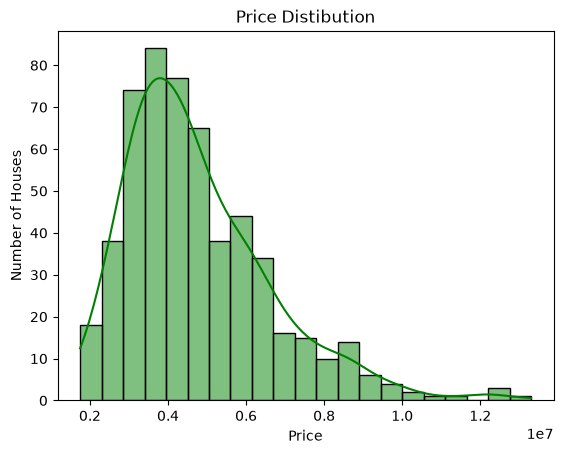

In [30]:
sns.histplot(df['Price'],kde=True,color='green')
plt.title("Price Distibution")
plt.xlabel("Price")
plt.ylabel("Number of Houses")
plt.show()

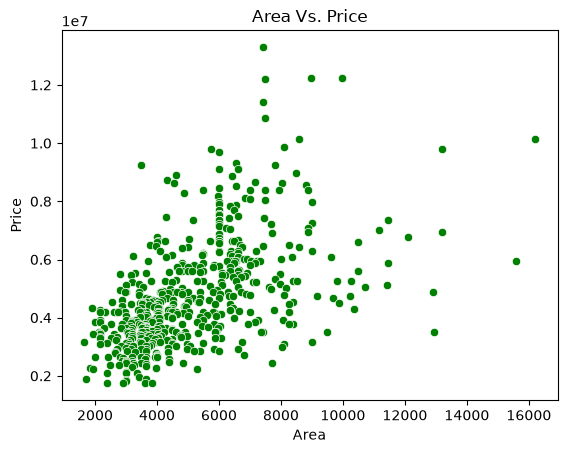

In [32]:
sns.scatterplot(x="Area",y="Price",data=df,color='green')
plt.title("Area Vs. Price")
plt.show()

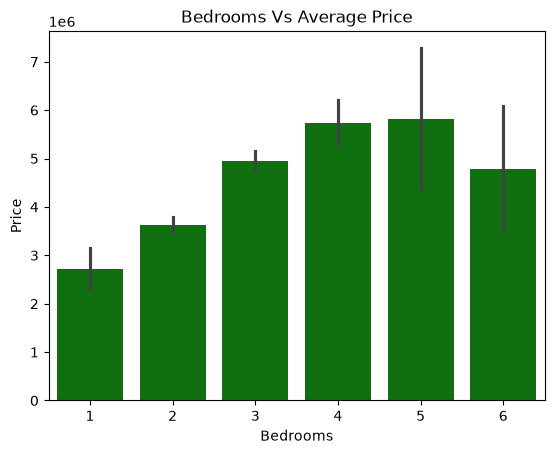

In [33]:
sns.barplot(x="Bedrooms",y="Price",data=df,color="green")
plt.title('Bedrooms Vs Average Price')
plt.show()

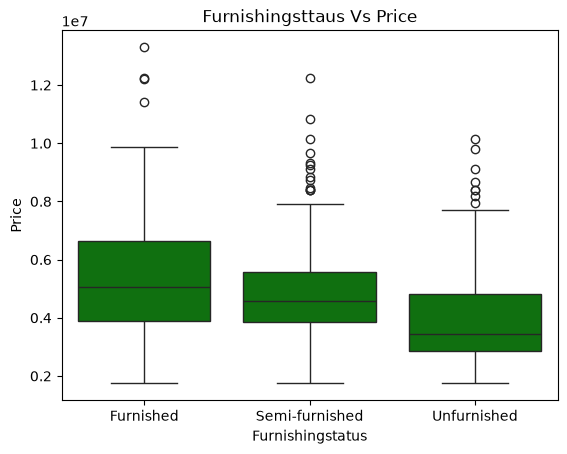

In [34]:
sns.boxplot(x='Furnishingstatus',y='Price',data=df,color='green')
plt.title('Furnishingsttaus Vs Price')
plt.show()

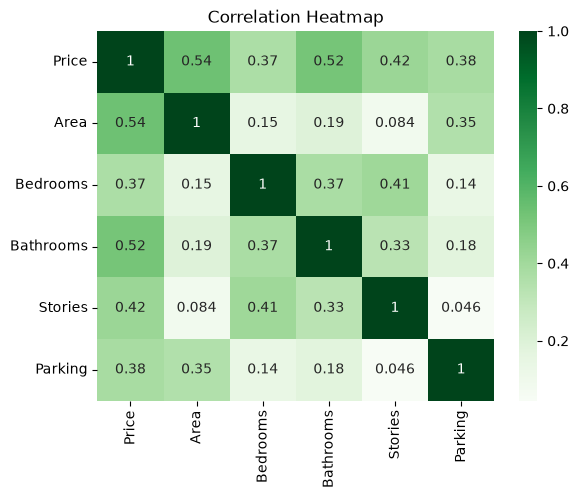

In [41]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='Greens')
plt.title('Correlation Heatmap')
plt.show()

# Insights:
1. Price Data is right-skewed,most houses priced between 30-60 lakhs,with only few houses priced above 1 crore.
2. As Area increases,Price also increases-there is a positive relationship between Area and Price.
3. As a number of bedrooms increases,the average Price also increases.
4. Furnished houses are priced more compared to Unfurnished houses.
5. Area has the strongest relationship with Price among all numeric features.(Highest Correlation value)

# Task 2 completed:Exploratory Data Analysis

In [42]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()
categorical_cols = ['Mainroad','Guestroom','Basement','Hotwaterheating','Airconditioning','Prefarea','Furnishingstatus']

for col in categorical_cols:
    df[col]=le.fit_transform(df[col])

In [43]:
display(df)

,Price,Area,Bedrooms,Bathrooms,Stories,Mainroad,Guestroom,Basement,Hotwaterheating,Airconditioning,Parking,Prefarea,Furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,2
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,1
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,2
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,0


In [44]:
X=df.drop('Price',axis=1)
X

,Area,Bedrooms,Bathrooms,Stories,Mainroad,Guestroom,Basement,Hotwaterheating,Airconditioning,Parking,Prefarea,Furnishingstatus
0,7420,4,2,3,1,0,0,0,1,2,1,0
1,8960,4,4,4,1,0,0,0,1,3,0,0
2,9960,3,2,2,1,0,1,0,0,2,1,1
3,7500,4,2,2,1,0,1,0,1,3,1,0
4,7420,4,1,2,1,1,1,0,1,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
540,3000,2,1,1,1,0,1,0,0,2,0,2
541,2400,3,1,1,0,0,0,0,0,0,0,1
542,3620,2,1,1,1,0,0,0,0,0,0,2
543,2910,3,1,1,0,0,0,0,0,0,0,0


In [45]:
y=df['Price']
y

0      13300000
1      12250000
2      12250000
3      12215000
4      11410000
         ...   
540     1820000
541     1767150
542     1750000
543     1750000
544     1750000
Name: Price, Length: 545, dtype: int64

In [46]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [47]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 235.85, 78574.49,1097117.27,..., 225756.51, 629901.66,-210397.12]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Area','Bedrooms','Bathrooms',...,'Parking','Prefarea','Furnishingstatus']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.931e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [48]:
y_pred=model.predict(X_test)

In [50]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 979679.6912959903
RMSE: 1331071.4167895105
R2: 0.6494754192267804


In [51]:
from sklearn.ensemble import RandomForestRegressor

rf_model= RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf=rf_model.predict(X_test)

print("RF MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RF RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("RF R2:", r2_score(y_test, y_pred_rf))

RF MAE: 1025289.6821100918
RF RMSE: 1401263.0789821919
RF R2: 0.6115321143409216


## Model Evaltion Result:
The Linear Regression model achieved a lower error and higher R² Score 
compared to Random Forest, making it the better-performing baseline 
model for this dataset.

# Task 3 completed:Modeling and Evalution

## Conclusion

This project covered the complete data science workflow — from data 
cleaning to exploratory analysis to predictive modeling.

Key takeaways:
- The dataset had no missing values or duplicates, but contained some 
  outliers in Price and Area.
- Area and Bathrooms showed the strongest correlation with Price.
- A baseline Linear Regression model achieved an R² of 0.65, 
  outperforming a Random Forest model (R² = 0.61).
- Future improvements could include adding location data and trying 
  advanced algorithms like Gradient Boosting.